
# Settlement & Payment Performance Analysis

## Objective

Evaluate insurance claim settlement and payment performance using historical claims and payment records.

### Key Analysis Areas

- Payment processing timelines
- Payment delays and turnaround time
- Payment method distribution
- Settlement and payment efficiency
- Operational bottlenecks and improvement opportunities

**Note:** Claim settlement dates are not available in the current dataset. Payment turnaround time will therefore be measured using claim and payment dates, without assuming that payment dates represent settlement dates.


In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL
from getpass import getpass

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 3 — MySQL Database Connection

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter MySQL Password: "),
    host="localhost",
    port=3306,
    database="insurance_claims_analytics"
)

engine = create_engine(db_url)

# Test database connection
with engine.connect() as connection:
    print("MySQL database connected successfully!")


MySQL database connected successfully!


In [3]:

# Step 4 — Load Claims and Payments Data

claims = pd.read_sql("SELECT * FROM claims", engine)
payments = pd.read_sql("SELECT * FROM payments", engine)

# Verify dataset dimensions
print("Claims Shape:", claims.shape)
print("Payments Shape:", payments.shape)

# Preview datasets
print("\nClaims Data:")
display(claims.head())

print("\nPayments Data:")
display(payments.head())


Claims Shape: (25000, 7)
Payments Shape: (15541, 5)

Claims Data:


,Claim_ID,Policy_ID,Claim_Date,Claim_Amount,Claim_Status,Fraud_Flag,Claim_Type
0,1,2178,2023-12-30,"24,036.53",Settled,0,Health
1,10,13007,2025-12-01,"22,231.96",Pending,0,Auto
2,100,4230,2022-06-12,"199,822.58",Settled,0,Home
3,1000,4551,2024-03-20,"26,982.02",Approved,0,Auto
4,10000,13435,2024-01-03,"84,148.58",Settled,0,Health



Payments Data:


,Payment_ID,Claim_ID,Payment_Date,Payment_Amount,Payment_Method
0,1,23669,2022-10-12,"9,759.10",Bank Transfer
1,10,20841,2022-09-01,"2,206.71",Bank Transfer
2,100,19092,2022-05-04,"19,946.47",UPI
3,1000,18441,2024-01-09,"16,415.77",UPI
4,10000,3598,2022-08-09,"51,067.06",UPI


In [4]:

# Step 5 — Validate Dates and Payment Relationships

# Convert date columns
claims["Claim_Date"] = pd.to_datetime(claims["Claim_Date"])
payments["Payment_Date"] = pd.to_datetime(payments["Payment_Date"])

# Check missing dates
print("Missing Claim Dates:", claims["Claim_Date"].isna().sum())
print("Missing Payment Dates:", payments["Payment_Date"].isna().sum())

# Check payment references
invalid_payment_claims = (
    ~payments["Claim_ID"].isin(claims["Claim_ID"])
).sum()

print("Payments With Invalid Claim IDs:", invalid_payment_claims)

# Check duplicate identifiers
print("Duplicate Claim IDs:", claims["Claim_ID"].duplicated().sum())
print("Duplicate Payment IDs:", payments["Payment_ID"].duplicated().sum())

# Check date ranges
print("\nClaim Date Range:")
print(claims["Claim_Date"].min(), "to", claims["Claim_Date"].max())

print("\nPayment Date Range:")
print(payments["Payment_Date"].min(), "to", payments["Payment_Date"].max())


Missing Claim Dates: 0
Missing Payment Dates: 0
Payments With Invalid Claim IDs: 0
Duplicate Claim IDs: 0
Duplicate Payment IDs: 0

Claim Date Range:
2020-01-05 00:00:00 to 2026-09-30 00:00:00

Payment Date Range:
2020-02-13 00:00:00 to 2026-12-24 00:00:00


In [5]:

# BR 1 — Payment Turnaround Time

# Join payment records with their corresponding claims
payment_tat = payments.merge(
    claims[["Claim_ID", "Claim_Date"]],
    on="Claim_ID",
    how="left",
    validate="many_to_one"
)

# Calculate days between claim date and payment date
payment_tat["Turnaround_Days"] = (
    payment_tat["Payment_Date"] - payment_tat["Claim_Date"]
).dt.days

# Check chronological validity
print(
    "Payments Before Claim Date:",
    (payment_tat["Turnaround_Days"] < 0).sum()
)

# Identify payments beyond the reporting cutoff
reporting_cutoff = pd.Timestamp("2026-09-30")

print(
    "Payments After Reporting Cutoff:",
    (payment_tat["Payment_Date"] > reporting_cutoff).sum()
)

# Calculate turnaround statistics for valid in-period payments
valid_payments = payment_tat[
    (payment_tat["Turnaround_Days"] >= 0)
    & (payment_tat["Payment_Date"] <= reporting_cutoff)
].copy()

print("\nPayment Turnaround Time (Days):")

display(
    valid_payments["Turnaround_Days"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)


Payments Before Claim Date: 0
Payments After Reporting Cutoff: 189

Payment Turnaround Time (Days):


count    15,352.00
mean         44.91
median       45.00
min           1.00
max          90.00
std          25.95
Name: Turnaround_Days, dtype: float64

In [6]:

# BR 2 — Payment Turnaround Distribution

# Categorize valid payments by turnaround time
payment_distribution = valid_payments.copy()

payment_distribution["Turnaround_Category"] = pd.cut(
    payment_distribution["Turnaround_Days"],
    bins=[-1, 30, 60, float("inf")],
    labels=["Within 30 Days", "31-60 Days", "Over 60 Days"]
)

# Summarize payment records by turnaround category
turnaround_analysis = (
    payment_distribution.groupby(
        "Turnaround_Category", observed=True
    )
    .agg(
        Total_Payments=("Payment_ID", "count"),
        Total_Payment_Amount=("Payment_Amount", "sum")
    )
    .reset_index()
)

# Calculate percentage of payment records
turnaround_analysis["Payment_Share_Pct"] = (
    turnaround_analysis["Total_Payments"]
    / turnaround_analysis["Total_Payments"].sum() * 100
)

display(turnaround_analysis.round(2))

print(
    "Total Payments:",
    turnaround_analysis["Total_Payments"].sum()
)

print(
    "Total Payment Share (%):",
    round(turnaround_analysis["Payment_Share_Pct"].sum(), 2)
)


,Turnaround_Category,Total_Payments,Total_Payment_Amount,Payment_Share_Pct
0,Within 30 Days,5275,"170,182,863.33",34.36
1,31-60 Days,5097,"169,278,100.17",33.20
2,Over 60 Days,4980,"160,677,342.94",32.44


Total Payments: 15352
Total Payment Share (%): 100.0


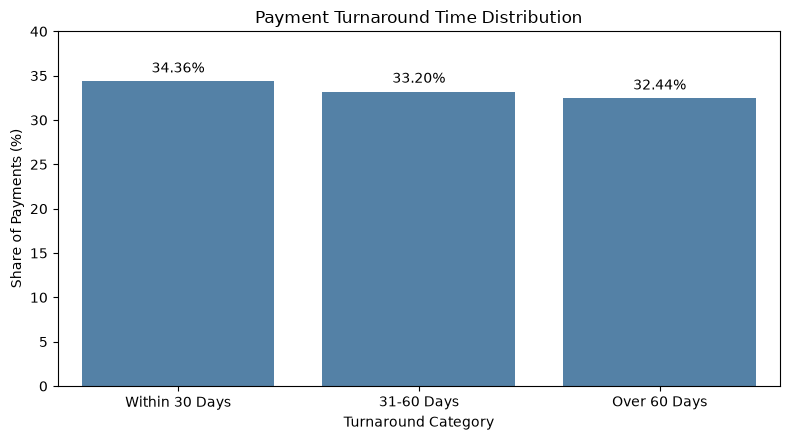

In [7]:

# BR 2 — Payment Turnaround Distribution Chart

plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=turnaround_analysis,
    x="Turnaround_Category",
    y="Payment_Share_Pct",
    color="steelblue"
)

# Display percentage labels
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Payment Turnaround Time Distribution")
plt.xlabel("Turnaround Category")
plt.ylabel("Share of Payments (%)")
plt.ylim(0, 40)
plt.tight_layout()
plt.show()


In [8]:

# BR 3 — Payment Turnaround by Claim Status

# Add claim status to valid payment records
payment_status_tat = valid_payments.merge(
    claims[["Claim_ID", "Claim_Status"]],
    on="Claim_ID",
    how="left",
    validate="many_to_one"
)

# Summarize turnaround time by claim status
status_tat_analysis = (
    payment_status_tat.groupby("Claim_Status")
    .agg(
        Total_Payments=("Payment_ID", "count"),
        Average_Turnaround_Days=("Turnaround_Days", "mean"),
        Median_Turnaround_Days=("Turnaround_Days", "median"),
        Max_Turnaround_Days=("Turnaround_Days", "max")
    )
    .reset_index()
)

display(
    status_tat_analysis.sort_values(
        "Average_Turnaround_Days",
        ascending=False
    ).round(2)
)

print(
    "Total Payments:",
    status_tat_analysis["Total_Payments"].sum()
)


,Claim_Status,Total_Payments,Average_Turnaround_Days,Median_Turnaround_Days,Max_Turnaround_Days
1,Settled,9710,44.95,45.00,90
0,Approved,5642,44.84,44.00,90


Total Payments: 15352


In [9]:

# BR 4 — Payment Method Performance

payment_method_analysis = (
    valid_payments.groupby("Payment_Method")
    .agg(
        Total_Payments=("Payment_ID", "count"),
        Total_Payment_Amount=("Payment_Amount", "sum"),
        Average_Turnaround_Days=("Turnaround_Days", "mean"),
        Median_Turnaround_Days=("Turnaround_Days", "median")
    )
    .reset_index()
)

# Calculate payment method usage percentage
payment_method_analysis["Payment_Share_Pct"] = (
    payment_method_analysis["Total_Payments"]
    / payment_method_analysis["Total_Payments"].sum() * 100
)

# Sort by payment volume
payment_method_analysis = payment_method_analysis.sort_values(
    "Total_Payments", ascending=False
)

display(payment_method_analysis.round(2))

print(
    "Total Payments:",
    payment_method_analysis["Total_Payments"].sum()
)

print(
    "Total Payment Share (%):",
    round(payment_method_analysis["Payment_Share_Pct"].sum(), 2)
)


,Payment_Method,Total_Payments,Total_Payment_Amount,Average_Turnaround_Days,Median_Turnaround_Days,Payment_Share_Pct
0,Bank Transfer,11019,"359,362,861.86",44.92,45.00,71.78
2,UPI,2490,"79,964,698.26",45.62,45.00,16.22
1,Cheque,1843,"60,810,746.32",43.89,42.00,12.00


Total Payments: 15352
Total Payment Share (%): 100.0


In [10]:

# BR 5 — Annual Payment Turnaround Performance

# Create payment year
payment_yearly = valid_payments.copy()

payment_yearly["Payment_Year"] = (
    payment_yearly["Payment_Date"].dt.year
)

# Calculate annual payment performance
yearly_tat_analysis = (
    payment_yearly.groupby("Payment_Year")
    .agg(
        Total_Payments=("Payment_ID", "count"),
        Average_Turnaround_Days=("Turnaround_Days", "mean"),
        Median_Turnaround_Days=("Turnaround_Days", "median"),
        Payments_Within_30_Days=(
            "Turnaround_Days",
            lambda x: (x <= 30).sum()
        )
    )
    .reset_index()
)

# Calculate percentage completed within 30 days
yearly_tat_analysis["Within_30_Days_Pct"] = (
    yearly_tat_analysis["Payments_Within_30_Days"]
    / yearly_tat_analysis["Total_Payments"] * 100
)

display(yearly_tat_analysis.round(2))

print(
    "Total Payments:",
    yearly_tat_analysis["Total_Payments"].sum()
)


,Payment_Year,Total_Payments,Average_Turnaround_Days,Median_Turnaround_Days,Payments_Within_30_Days,Within_30_Days_Pct
0,2020,789,40.60,38.00,319,40.43
1,2021,2292,43.87,43.00,820,35.78
2,2022,2572,44.93,45.00,889,34.56
3,2023,2567,45.72,46.00,852,33.19
4,2024,2686,45.17,45.00,904,33.66
5,2025,2664,44.91,45.00,924,34.68
6,2026,1782,46.57,47.00,567,31.82


Total Payments: 15352


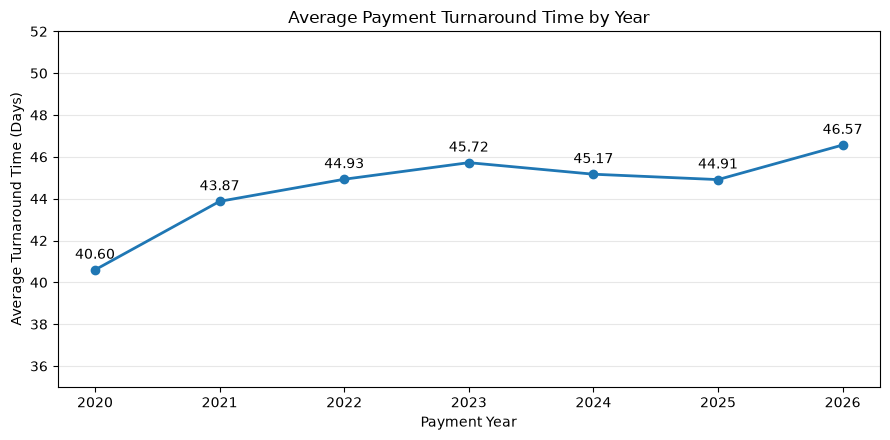

In [11]:

# BR 5 — Annual Payment Turnaround Trend

plt.figure(figsize=(9, 4.5))

plt.plot(
    yearly_tat_analysis["Payment_Year"],
    yearly_tat_analysis["Average_Turnaround_Days"],
    marker="o",
    linewidth=2
)

# Add value labels
for year, tat in zip(
    yearly_tat_analysis["Payment_Year"],
    yearly_tat_analysis["Average_Turnaround_Days"]
):
    plt.annotate(
        f"{tat:.2f}",
        (year, tat),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title("Average Payment Turnaround Time by Year")
plt.xlabel("Payment Year")
plt.ylabel("Average Turnaround Time (Days)")
plt.xticks(yearly_tat_analysis["Payment_Year"])
plt.ylim(35, 52)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# BR 6 — Payment Amount vs Turnaround Time

# Calculate correlation between payment amount and turnaround days
payment_amount_correlation = valid_payments[
    ["Payment_Amount", "Turnaround_Days"]
].corr(method="pearson").loc[
    "Payment_Amount", "Turnaround_Days"
]

payment_amount_spearman = valid_payments[
    ["Payment_Amount", "Turnaround_Days"]
].corr(method="spearman").loc[
    "Payment_Amount", "Turnaround_Days"
]

print(
    "Pearson Correlation:",
    round(payment_amount_correlation, 4)
)

print(
    "Spearman Correlation:",
    round(payment_amount_spearman, 4)
)


Pearson Correlation: 0.0014
Spearman Correlation: -0.0069


In [13]:

# BR 7 — Payment Delays by Claim Type

# Add claim type to valid payment records
payment_claim_type = valid_payments.merge(
    claims[["Claim_ID", "Claim_Type"]],
    on="Claim_ID",
    how="left",
    validate="many_to_one"
)

# Summarize payment performance by claim type
claim_type_tat = (
    payment_claim_type.groupby("Claim_Type")
    .agg(
        Total_Payments=("Payment_ID", "count"),
        Average_Turnaround_Days=("Turnaround_Days", "mean"),
        Median_Turnaround_Days=("Turnaround_Days", "median"),
        Payments_Over_60_Days=(
            "Turnaround_Days",
            lambda x: (x > 60).sum()
        )
    )
    .reset_index()
)

# Calculate percentage of payments taking over 60 days
claim_type_tat["Over_60_Days_Pct"] = (
    claim_type_tat["Payments_Over_60_Days"]
    / claim_type_tat["Total_Payments"] * 100
)

# Sort by average turnaround time
claim_type_tat = claim_type_tat.sort_values(
    "Average_Turnaround_Days",
    ascending=False
)

display(claim_type_tat.round(2))

print("Total Payments:", claim_type_tat["Total_Payments"].sum())


,Claim_Type,Total_Payments,Average_Turnaround_Days,Median_Turnaround_Days,Payments_Over_60_Days,Over_60_Days_Pct
1,Health,4772,45.08,45.00,1556,32.61
3,Life,1813,44.90,44.00,584,32.21
0,Auto,6016,44.87,44.00,1953,32.46
2,Home,2751,44.70,45.00,887,32.24


Total Payments: 15352


In [14]:

# BR 8 — First Payment Turnaround Time

# Identify the earliest in-period payment for each claim
first_payments = (
    valid_payments.groupby("Claim_ID")
    .agg(
        First_Payment_Date=("Payment_Date", "min")
    )
    .reset_index()
)

# Join with claim submission dates
first_payment_analysis = first_payments.merge(
    claims[["Claim_ID", "Claim_Date"]],
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# Calculate first-payment turnaround time
first_payment_analysis["First_Payment_TAT"] = (
    first_payment_analysis["First_Payment_Date"]
    - first_payment_analysis["Claim_Date"]
).dt.days

# Summarize turnaround time
display(
    first_payment_analysis["First_Payment_TAT"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print(
    "Claims With First Payment:",
    len(first_payment_analysis)
)

print(
    "Claims Without In-Period Payment:",
    len(claims) - len(first_payment_analysis)
)


count    15,352.00
mean         44.91
median       45.00
min           1.00
max          90.00
std          25.95
Name: First_Payment_TAT, dtype: float64

Claims With First Payment: 15352
Claims Without In-Period Payment: 9648


In [15]:

# BR 9 — First-Payment Performance by Claim Year

# Create claim submission year
claim_year_payment = first_payment_analysis.copy()

claim_year_payment["Claim_Year"] = (
    claim_year_payment["Claim_Date"].dt.year
)

# Summarize first-payment turnaround by claim year
claim_year_tat = (
    claim_year_payment.groupby("Claim_Year")
    .agg(
        Claims_With_Payment=("Claim_ID", "count"),
        Average_First_Payment_Days=("First_Payment_TAT", "mean"),
        Median_First_Payment_Days=("First_Payment_TAT", "median"),
        Claims_Paid_Within_30_Days=(
            "First_Payment_TAT",
            lambda x: (x <= 30).sum()
        )
    )
    .reset_index()
)

# Calculate within-30-day share
claim_year_tat["Within_30_Days_Pct"] = (
    claim_year_tat["Claims_Paid_Within_30_Days"]
    / claim_year_tat["Claims_With_Payment"] * 100
)

display(claim_year_tat.round(2))

print(
    "Total Claims With Payment:",
    claim_year_tat["Claims_With_Payment"].sum()
)


,Claim_Year,Claims_With_Payment,Average_First_Payment_Days,Median_First_Payment_Days,Claims_Paid_Within_30_Days,Within_30_Days_Pct
0,2020,1042,45.65,44.50,353,33.88
1,2021,2337,44.03,43.00,820,35.09
2,2022,2573,44.87,45.00,898,34.90
3,2023,2587,46.06,47.00,850,32.86
4,2024,2737,45.24,45.00,915,33.43
5,2025,2642,44.85,44.50,908,34.37
6,2026,1434,43.29,42.00,531,37.03


Total Claims With Payment: 15352


In [16]:

# BR 10 — First-Payment Performance by Claim Amount Band

# Add claim amount to first-payment data
claim_amount_tat = first_payment_analysis.merge(
    claims[["Claim_ID", "Claim_Amount"]],
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# Divide claims into four claim amount groups
claim_amount_tat["Claim_Amount_Band"] = pd.qcut(
    claim_amount_tat["Claim_Amount"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Summarize first-payment turnaround by amount band
claim_amount_band_analysis = (
    claim_amount_tat.groupby("Claim_Amount_Band", observed=True)
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Average_Claim_Amount=("Claim_Amount", "mean"),
        Average_First_Payment_Days=("First_Payment_TAT", "mean"),
        Median_First_Payment_Days=("First_Payment_TAT", "median")
    )
    .reset_index()
)

display(claim_amount_band_analysis.round(2))

print(
    "Total Claims:",
    claim_amount_band_analysis["Total_Claims"].sum()
)


,Claim_Amount_Band,Total_Claims,Average_Claim_Amount,Average_First_Payment_Days,Median_First_Payment_Days
0,Low,3838,"10,871.20",45.54,46.00
1,Lower-Middle,3838,"22,939.71",44.65,44.00
2,Upper-Middle,3838,"39,469.70",44.33,44.00
3,High,3838,"94,301.28",45.13,45.00


Total Claims: 15352


In [17]:

# BR 11 — Payment Timeliness by Fraud Flag

# Add fraud flag to first-payment records
fraud_payment_tat = first_payment_analysis.merge(
    claims[["Claim_ID", "Fraud_Flag"]],
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# Summarize first-payment performance by fraud flag
fraud_tat_analysis = (
    fraud_payment_tat.groupby("Fraud_Flag")
    .agg(
        Claims_With_Payment=("Claim_ID", "count"),
        Average_First_Payment_Days=("First_Payment_TAT", "mean"),
        Median_First_Payment_Days=("First_Payment_TAT", "median"),
        Payments_Over_60_Days=(
            "First_Payment_TAT",
            lambda x: (x > 60).sum()
        )
    )
    .reset_index()
)

# Calculate percentage taking over 60 days
fraud_tat_analysis["Over_60_Days_Pct"] = (
    fraud_tat_analysis["Payments_Over_60_Days"]
    / fraud_tat_analysis["Claims_With_Payment"] * 100
)

# Add readable labels
fraud_tat_analysis["Fraud_Category"] = (
    fraud_tat_analysis["Fraud_Flag"].map({
        0: "Not Flagged",
        1: "Fraud Flagged"
    })
)

display(
    fraud_tat_analysis[
        [
            "Fraud_Category",
            "Claims_With_Payment",
            "Average_First_Payment_Days",
            "Median_First_Payment_Days",
            "Payments_Over_60_Days",
            "Over_60_Days_Pct"
        ]
    ].round(2)
)

print(
    "Total Claims With Payment:",
    fraud_tat_analysis["Claims_With_Payment"].sum()
)


,Fraud_Category,Claims_With_Payment,Average_First_Payment_Days,Median_First_Payment_Days,Payments_Over_60_Days,Over_60_Days_Pct
0,Not Flagged,14806,44.91,45.00,4805,32.45
1,Fraud Flagged,546,44.80,44.50,175,32.05


Total Claims With Payment: 15352


In [18]:

# BR 12 — Payment Coverage by Claim Status

# Identify claims with an in-period payment
paid_claim_ids = set(valid_payments["Claim_ID"])

# Include all claims, including those without payment
claim_payment_coverage = claims[
    ["Claim_ID", "Claim_Status"]
].copy()

# Flag whether each claim received a payment
claim_payment_coverage["Has_Payment"] = (
    claim_payment_coverage["Claim_ID"].isin(paid_claim_ids)
)

# Calculate payment coverage by claim status
payment_coverage_analysis = (
    claim_payment_coverage.groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Claims_With_Payment=("Has_Payment", "sum")
    )
    .reset_index()
)

# Calculate claims without payment
payment_coverage_analysis["Claims_Without_Payment"] = (
    payment_coverage_analysis["Total_Claims"]
    - payment_coverage_analysis["Claims_With_Payment"]
)

# Calculate payment coverage percentage
payment_coverage_analysis["Payment_Coverage_Pct"] = (
    payment_coverage_analysis["Claims_With_Payment"]
    / payment_coverage_analysis["Total_Claims"] * 100
)

display(payment_coverage_analysis.round(2))

print(
    "Total Claims:",
    payment_coverage_analysis["Total_Claims"].sum()
)

print(
    "Claims With Payment:",
    payment_coverage_analysis["Claims_With_Payment"].sum()
)

print(
    "Claims Without Payment:",
    payment_coverage_analysis["Claims_Without_Payment"].sum()
)


,Claim_Status,Total_Claims,Claims_With_Payment,Claims_Without_Payment,Payment_Coverage_Pct
0,Approved,6100,5642,458,92.49
1,Pending,4075,0,4075,0.00
2,Rejected,4256,0,4256,0.00
3,Settled,10569,9710,859,91.87


Total Claims: 25000
Claims With Payment: 15352
Claims Without Payment: 9648


In [19]:

# BR 13 — Unpaid Approved and Settled Claims

# Identify approved or settled claims without in-period payments
unpaid_finalized_claims = claims[
    claims["Claim_Status"].isin(["Approved", "Settled"])
    & ~claims["Claim_ID"].isin(valid_payments["Claim_ID"])
].copy()

# Summarize by claim status
unpaid_claim_analysis = (
    unpaid_finalized_claims.groupby("Claim_Status")
    .agg(
        Unpaid_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Average_Claim_Amount=("Claim_Amount", "mean"),
        Median_Claim_Amount=("Claim_Amount", "median")
    )
    .reset_index()
)

display(unpaid_claim_analysis.round(2))

print(
    "Total Unpaid Approved/Settled Claims:",
    len(unpaid_finalized_claims)
)

print(
    "Total Associated Claim Amount:",
    round(unpaid_finalized_claims["Claim_Amount"].sum(), 2)
)


,Claim_Status,Unpaid_Claims,Total_Claim_Amount,Average_Claim_Amount,Median_Claim_Amount
0,Approved,458,"19,876,882.88","43,399.31","30,749.50"
1,Settled,859,"37,111,882.78","43,203.59","30,463.78"


Total Unpaid Approved/Settled Claims: 1317
Total Associated Claim Amount: 56988765.66


In [20]:

# BR 14 — Unpaid Claim Aging Analysis

# Use previously identified unpaid Approved and Settled claims
unpaid_aging = unpaid_finalized_claims.copy()

# Calculate claim age as of reporting cutoff
unpaid_aging["Claim_Age_Days"] = (
    reporting_cutoff - unpaid_aging["Claim_Date"]
).dt.days

# Exclude future-dated claims, if any
unpaid_aging = unpaid_aging[
    unpaid_aging["Claim_Age_Days"] >= 0
].copy()

# Create aging categories
unpaid_aging["Aging_Band"] = pd.cut(
    unpaid_aging["Claim_Age_Days"],
    bins=[-1, 30, 60, 90, float("inf")],
    labels=["0-30 Days", "31-60 Days", "61-90 Days", "Over 90 Days"]
)

# Summarize unpaid claims by aging category
unpaid_aging_analysis = (
    unpaid_aging.groupby("Aging_Band", observed=True)
    .agg(
        Unpaid_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Average_Claim_Age=("Claim_Age_Days", "mean")
    )
    .reset_index()
)

# Calculate percentage distribution
unpaid_aging_analysis["Claims_Pct"] = (
    unpaid_aging_analysis["Unpaid_Claims"]
    / len(unpaid_aging) * 100
)

display(unpaid_aging_analysis.round(2))

print("Total Claims Analyzed:", len(unpaid_aging))
print("Oldest Claim Age:", unpaid_aging["Claim_Age_Days"].max())


,Aging_Band,Unpaid_Claims,Total_Claim_Amount,Average_Claim_Age,Claims_Pct
0,0-30 Days,112,"4,897,722.78",15.82,8.50
1,31-60 Days,66,"2,769,976.87",44.94,5.01
2,61-90 Days,37,"1,654,160.10",73.22,2.81
3,Over 90 Days,1102,"47,666,905.91","1,123.87",83.68


Total Claims Analyzed: 1317
Oldest Claim Age: 2434


In [21]:

# BR 15 — Unpaid Claim Aging by Status

# Summarize unpaid claims by status and aging band
status_aging_analysis = (
    unpaid_aging.groupby(
        ["Claim_Status", "Aging_Band"],
        observed=True
    )
    .agg(
        Unpaid_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum")
    )
    .reset_index()
)

# Calculate percentage within each claim status
status_aging_analysis["Status_Total"] = (
    status_aging_analysis.groupby("Claim_Status")[
        "Unpaid_Claims"
    ].transform("sum")
)

status_aging_analysis["Status_Aging_Pct"] = (
    status_aging_analysis["Unpaid_Claims"]
    / status_aging_analysis["Status_Total"] * 100
)

display(
    status_aging_analysis[
        [
            "Claim_Status",
            "Aging_Band",
            "Unpaid_Claims",
            "Total_Claim_Amount",
            "Status_Aging_Pct"
        ]
    ].round(2)
)

print(
    "Total Claims:",
    status_aging_analysis["Unpaid_Claims"].sum()
)

print(
    "Total Claim Amount:",
    round(status_aging_analysis["Total_Claim_Amount"].sum(), 2)
)


,Claim_Status,Aging_Band,Unpaid_Claims,Total_Claim_Amount,Status_Aging_Pct
0,Approved,0-30 Days,37,"1,476,451.59",8.08
1,Approved,31-60 Days,18,"829,527.91",3.93
2,Approved,61-90 Days,14,"498,276.13",3.06
3,Approved,Over 90 Days,389,"17,072,627.25",84.93
4,Settled,0-30 Days,75,"3,421,271.19",8.73
5,Settled,31-60 Days,48,"1,940,448.96",5.59
6,Settled,61-90 Days,23,"1,155,883.97",2.68
7,Settled,Over 90 Days,713,"30,594,278.66",83.00


Total Claims: 1317
Total Claim Amount: 56988765.66


In [22]:

# BR 16 — Payment Amount Coverage Against Claim Amount

# Aggregate in-period payment amounts by claim
claim_payment_totals = (
    valid_payments.groupby("Claim_ID")
    .agg(
        Total_Payment_Amount=("Payment_Amount", "sum")
    )
    .reset_index()
)

# Join original claim amounts
payment_amount_coverage = claim_payment_totals.merge(
    claims[["Claim_ID", "Claim_Amount", "Claim_Status"]],
    on="Claim_ID",
    how="left",
    validate="one_to_one"
)

# Calculate payment-to-claim ratio
payment_amount_coverage["Payment_Coverage_Pct"] = (
    payment_amount_coverage["Total_Payment_Amount"]
    / payment_amount_coverage["Claim_Amount"] * 100
)

# Summarize financial coverage by claim status
payment_amount_summary = (
    payment_amount_coverage.groupby("Claim_Status")
    .agg(
        Claims_With_Payment=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Total_Payment_Amount=("Total_Payment_Amount", "sum"),
        Average_Payment_Coverage_Pct=("Payment_Coverage_Pct", "mean")
    )
    .reset_index()
)

# Calculate overall amount-weighted coverage
payment_amount_summary["Weighted_Coverage_Pct"] = (
    payment_amount_summary["Total_Payment_Amount"]
    / payment_amount_summary["Total_Claim_Amount"] * 100
)

display(payment_amount_summary.round(2))

print(
    "Total Claims With Payment:",
    len(payment_amount_coverage)
)

print(
    "Claims With Payment Exceeding Claim Amount:",
    (
        payment_amount_coverage["Total_Payment_Amount"]
        > payment_amount_coverage["Claim_Amount"]
    ).sum()
)


,Claim_Status,Claims_With_Payment,Total_Claim_Amount,Total_Payment_Amount,Average_Payment_Coverage_Pct,Weighted_Coverage_Pct
0,Approved,5642,"232,582,405.95","180,696,892.24",77.45,77.69
1,Settled,9710,"410,596,896.07","319,441,414.20",77.65,77.80


Total Claims With Payment: 15352
Claims With Payment Exceeding Claim Amount: 0


In [23]:

# BR 17 — Payment Coverage Distribution

# Categorize claims by payment-to-claim ratio
payment_amount_coverage["Coverage_Band"] = pd.cut(
    payment_amount_coverage["Payment_Coverage_Pct"],
    bins=[-0.01, 25, 50, 75, 100],
    labels=[
        "0-25%",
        "25-50%",
        "50-75%",
        "75-100%"
    ],
    include_lowest=True
)

# Summarize claims by coverage band
coverage_distribution = (
    payment_amount_coverage.groupby(
        "Coverage_Band",
        observed=True
    )
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Total_Payment_Amount=("Total_Payment_Amount", "sum")
    )
    .reset_index()
)

# Calculate percentage of claims
coverage_distribution["Claims_Pct"] = (
    coverage_distribution["Total_Claims"]
    / len(payment_amount_coverage) * 100
)

display(coverage_distribution.round(2))

print(
    "Total Claims Analyzed:",
    coverage_distribution["Total_Claims"].sum()
)

print(
    "Minimum Coverage:",
    round(payment_amount_coverage["Payment_Coverage_Pct"].min(), 2)
)

print(
    "Maximum Coverage:",
    round(payment_amount_coverage["Payment_Coverage_Pct"].max(), 2)
)


,Coverage_Band,Total_Claims,Total_Claim_Amount,Total_Payment_Amount,Claims_Pct
0,50-75%,6812,"281,567,291.16","183,449,830.95",44.37
1,75-100%,8540,"361,612,010.86","316,688,475.49",55.63


Total Claims Analyzed: 15352
Minimum Coverage: 55.0
Maximum Coverage: 99.99


In [24]:

# BR 18 — Payment Performance KPI Summary

total_claims = len(claims)
claims_with_payment = valid_payments["Claim_ID"].nunique()
claims_without_payment = total_claims - claims_with_payment

total_payment_amount = valid_payments["Payment_Amount"].sum()

average_payment_tat = valid_payments["Turnaround_Days"].mean()
median_payment_tat = valid_payments["Turnaround_Days"].median()

within_30_days_pct = (
    valid_payments["Turnaround_Days"].le(30).mean() * 100
)

over_60_days_pct = (
    valid_payments["Turnaround_Days"].gt(60).mean() * 100
)

overall_payment_coverage = (
    payment_amount_coverage["Total_Payment_Amount"].sum()
    / payment_amount_coverage["Claim_Amount"].sum() * 100
)

# Create KPI summary
payment_kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Claims",
        "Claims With Payment",
        "Claims Without Payment",
        "Payment Record Coverage (%)",
        "Total In-Period Payment Amount",
        "Average Payment TAT (Days)",
        "Median Payment TAT (Days)",
        "Payments Within 30 Days (%)",
        "Payments Over 60 Days (%)",
        "Weighted Payment Amount Coverage (%)",
        "Unpaid Approved/Settled Claims",
        "Associated Claim Amount for Review"
    ],
    "Value": [
        total_claims,
        claims_with_payment,
        claims_without_payment,
        claims_with_payment / total_claims * 100,
        total_payment_amount,
        average_payment_tat,
        median_payment_tat,
        within_30_days_pct,
        over_60_days_pct,
        overall_payment_coverage,
        len(unpaid_finalized_claims),
        unpaid_finalized_claims["Claim_Amount"].sum()
    ]
})

display(payment_kpi_summary.round(2))


,KPI,Value
0,Total Claims,"25,000.00"
1,Claims With Payment,"15,352.00"
2,Claims Without Payment,"9,648.00"
3,Payment Record Coverage (%),61.41
4,Total In-Period Payment Amount,"500,138,306.44"
5,Average Payment TAT (Days),44.91
6,Median Payment TAT (Days),45.00
7,Payments Within 30 Days (%),34.36
8,Payments Over 60 Days (%),32.44
9,Weighted Payment Amount Coverage (%),77.76
